# Credit Card Fraud Detection

This notebook explores the `card_transdata.csv` dataset to understand how fraudulent transactions differ from legitimate ones, then builds a **K-Nearest Neighbors (KNN)** classifier with scikit-learn to predict whether a transaction is fraudulent.

**Dataset columns**

| Column | Type | Description |
|---|---|---|
| `distance_from_home` | continuous | Distance from home where the transaction happened |
| `distance_from_last_transaction` | continuous | Distance from where the last transaction happened |
| `ratio_to_median_purchase_price` | continuous | Purchase price divided by the cardholder's median purchase price |
| `repeat_retailer` | binary | Transaction happened at a retailer used before |
| `used_chip` | binary | Transaction used the card's chip |
| `used_pin_number` | binary | Transaction used a PIN number |
| `online_order` | binary | Transaction was an online order |
| `fraud` | binary (target) | 1 = fraudulent, 0 = legitimate |

**Outline**
1. Setup and data loading
2. Data quality checks
3. Exploratory analysis: target balance, continuous features, binary features, correlations
4. Preprocessing and train/test split
5. KNN model: baseline, hyperparameter tuning, evaluation
6. Conclusions

## 1. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
)

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# Consistent colors for the two classes throughout the notebook
CLASS_COLORS = {0: "#4C72B0", 1: "#DD5555"}
CLASS_NAMES = {0: "Legitimate", 1: "Fraud"}
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("card_transdata.csv")
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 999   Columns: 8


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.878,0.311,1.946,1.000,1.000,0.000,0.000,0
1,10.830,0.176,1.294,1.000,NaN,0.000,0.000,0
2,5.091,NaN,0.428,1.000,0.000,0.000,1.000,0
3,2.248,5.600,0.363,1.000,1.000,0.000,1.000,0
4,44.191,0.566,2.223,1.000,1.000,0.000,1.000,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB


## 2. Data quality checks

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
print(f"Duplicate rows: {df.duplicated().sum()}")
quality

Duplicate rows: 0


,dtype,missing,missing_%,unique_values
distance_from_home,float64,0,0.000,999
distance_from_last_transaction,float64,3,0.300,996
ratio_to_median_purchase_price,float64,2,0.200,997
repeat_retailer,float64,7,0.700,2
used_chip,float64,4,0.400,2
used_pin_number,float64,2,0.200,2
online_order,float64,4,0.400,2
fraud,int64,0,0.000,2


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
distance_from_home,999.000,26.877,63.900,0.104,3.991,10.340,25.394,965.911
distance_from_last_transaction,996.000,5.437,35.668,0.001,0.306,0.959,3.137,990.070
ratio_to_median_purchase_price,997.000,1.655,2.351,0.017,0.468,0.956,1.922,36.074
repeat_retailer,992.000,0.892,0.310,0.000,1.000,1.000,1.000,1.000
used_chip,995.000,0.314,0.464,0.000,0.000,0.000,1.000,1.000
used_pin_number,997.000,0.117,0.322,0.000,0.000,0.000,0.000,1.000
online_order,995.000,0.673,0.469,0.000,0.000,1.000,1.000,1.000
fraud,999.000,0.079,0.270,0.000,0.000,0.000,0.000,1.000


**Observations**
- A handful of values are missing in most feature columns (less than 1% per column). Rather than dropping rows, these will be **imputed** inside the modeling pipeline (median for continuous features, most frequent value for binary flags) so that no information from the test set leaks into training.
- The three distance/price features are heavily **right-skewed**: their maximum values are far larger than their 75th percentiles. This matters for KNN because it relies on distances between points.

In [6]:
TARGET = "fraud"
continuous_cols = ["distance_from_home", "distance_from_last_transaction", "ratio_to_median_purchase_price"]
binary_cols = ["repeat_retailer", "used_chip", "used_pin_number", "online_order"]
feature_cols = continuous_cols + binary_cols

## 3. Exploratory data analysis

### 3.1 Target variable: how common is fraud?

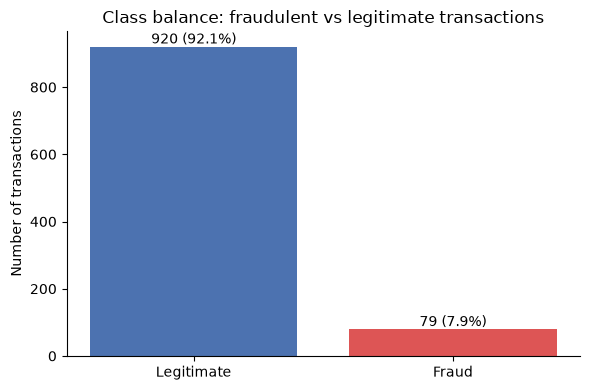

In [7]:
counts = df[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar([CLASS_NAMES[i] for i in counts.index], counts.values,
              color=[CLASS_COLORS[i] for i in counts.index])
for bar, c, p in zip(bars, counts.values, pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{c} ({p:.1f}%)",
            ha="center", va="bottom")
ax.set_title("Class balance: fraudulent vs legitimate transactions")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

The dataset is **imbalanced**: only about 8% of transactions are fraudulent. A model that always predicts "legitimate" would already be about 92% accurate, so accuracy alone is a misleading metric. We will focus on **recall** (share of fraud caught), **precision** (share of fraud alerts that are real), **F1**, and **ROC-AUC / PR-AUC**.

### 3.2 Continuous features by class

In [8]:
df.groupby(TARGET)[continuous_cols].agg(["mean", "median"]).rename(index=CLASS_NAMES).T

fraud                                  Legitimate  Fraud
distance_from_home             mean        21.277 92.093
                               median       9.595 19.614
distance_from_last_transaction mean         4.706 13.924
                               median       0.960  0.957
ratio_to_median_purchase_price mean         1.357  5.116
                               median       0.890  4.868

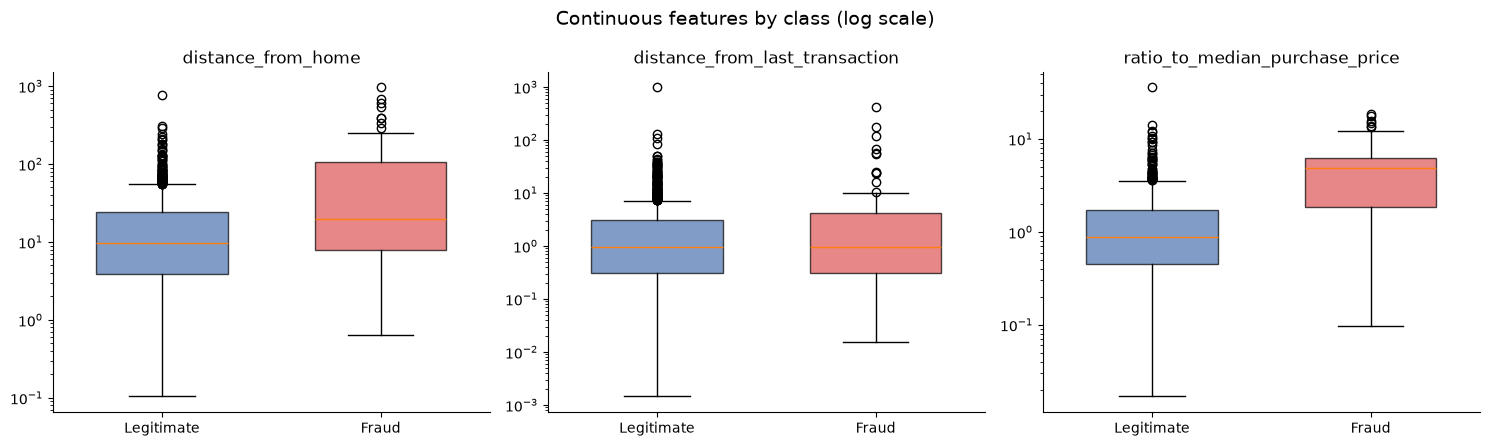

In [9]:
# Box plots on a log scale, since the raw values are extremely skewed
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, continuous_cols):
    data = [df.loc[df[TARGET] == k, col].dropna() for k in (0, 1)]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6)
    ax.set_xticks([1, 2], [CLASS_NAMES[0], CLASS_NAMES[1]])
    for patch, k in zip(bp["boxes"], (0, 1)):
        patch.set_facecolor(CLASS_COLORS[k]); patch.set_alpha(0.7)
    ax.set_yscale("log")
    ax.set_title(col)
fig.suptitle("Continuous features by class (log scale)", fontsize=14)
plt.tight_layout()
plt.show()

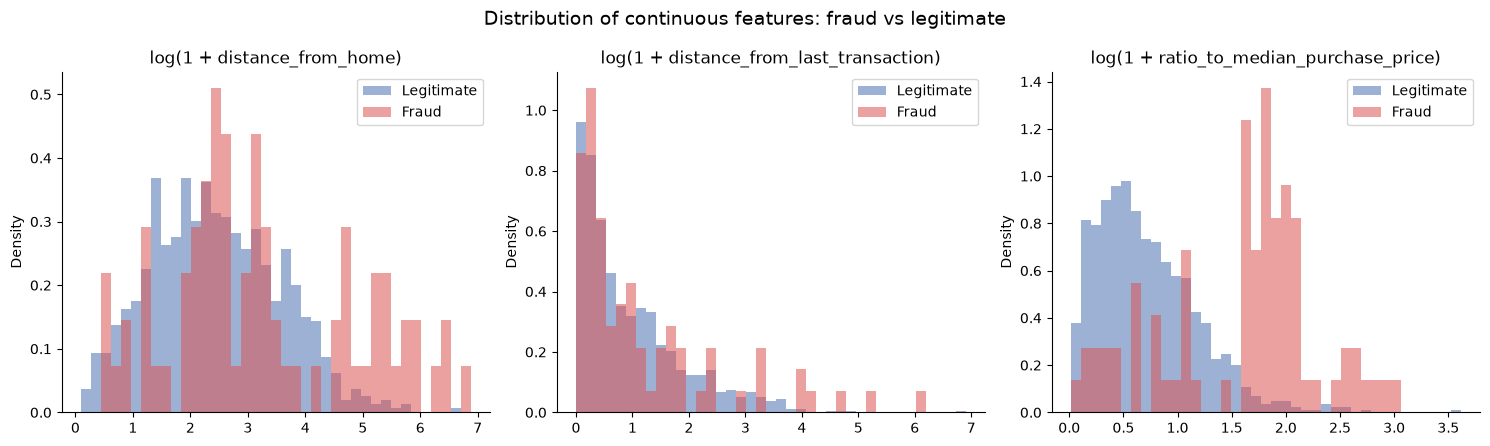

In [10]:
# Overlaid density histograms of log-transformed values
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, continuous_cols):
    logged = np.log1p(df[col])
    bins = np.linspace(logged.min(), logged.max(), 40)
    for k in (0, 1):
        ax.hist(logged[df[TARGET] == k].dropna(), bins=bins, density=True, alpha=0.55,
                color=CLASS_COLORS[k], label=CLASS_NAMES[k])
    ax.set_title(f"log(1 + {col})")
    ax.set_ylabel("Density")
    ax.legend()
fig.suptitle("Distribution of continuous features: fraud vs legitimate", fontsize=14)
plt.tight_layout()
plt.show()

**Observations**
- **`ratio_to_median_purchase_price`** shows the clearest separation: fraudulent purchases tend to be much larger than the cardholder's usual purchase.
- **`distance_from_home`** is also higher on average for fraud, meaning transactions far from home are more suspicious.
- **`distance_from_last_transaction`** shows a weaker but similar shift toward larger distances for fraud.

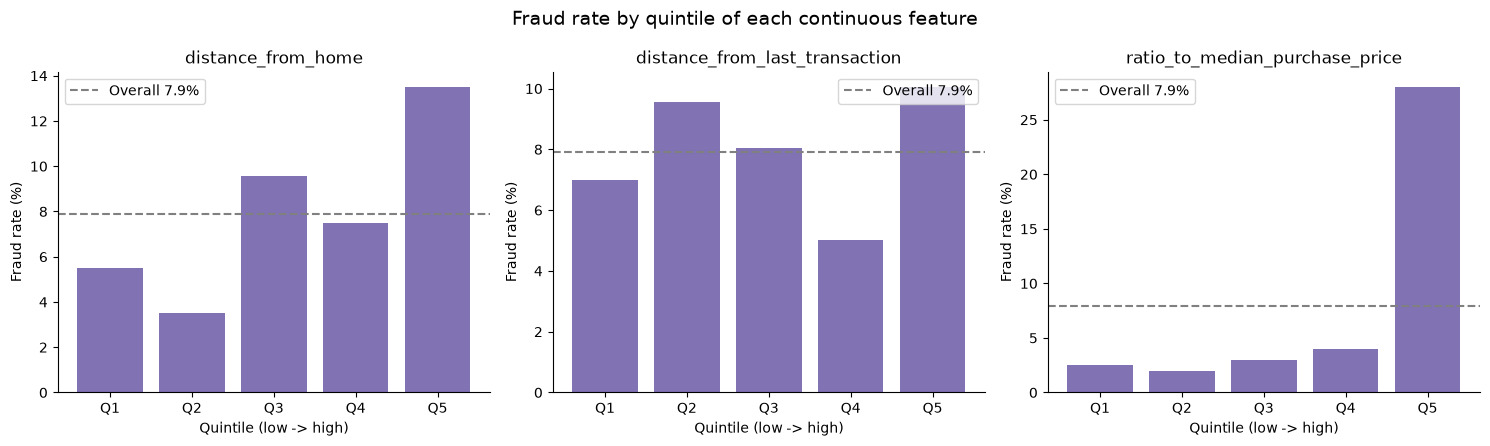

In [11]:
# Fraud rate across quantile bins of each continuous feature
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
overall_rate = df[TARGET].mean()
for ax, col in zip(axes, continuous_cols):
    binned = pd.qcut(df[col], q=5, duplicates="drop")
    rate = df.groupby(binned, observed=True)[TARGET].mean() * 100
    ax.bar(range(len(rate)), rate.values, color="#8172B3")
    ax.set_xticks(range(len(rate)), [f"Q{i+1}" for i in range(len(rate))])
    ax.axhline(overall_rate * 100, color="gray", ls="--", label=f"Overall {overall_rate:.1%}")
    ax.set_title(col)
    ax.set_xlabel("Quintile (low -> high)")
    ax.set_ylabel("Fraud rate (%)")
    ax.legend()
fig.suptitle("Fraud rate by quintile of each continuous feature", fontsize=14)
plt.tight_layout()
plt.show()

Splitting each feature into five equal-sized groups makes the relationship easy to read: the fraud rate climbs sharply in the top quintile of purchase-price ratio and distance from home.

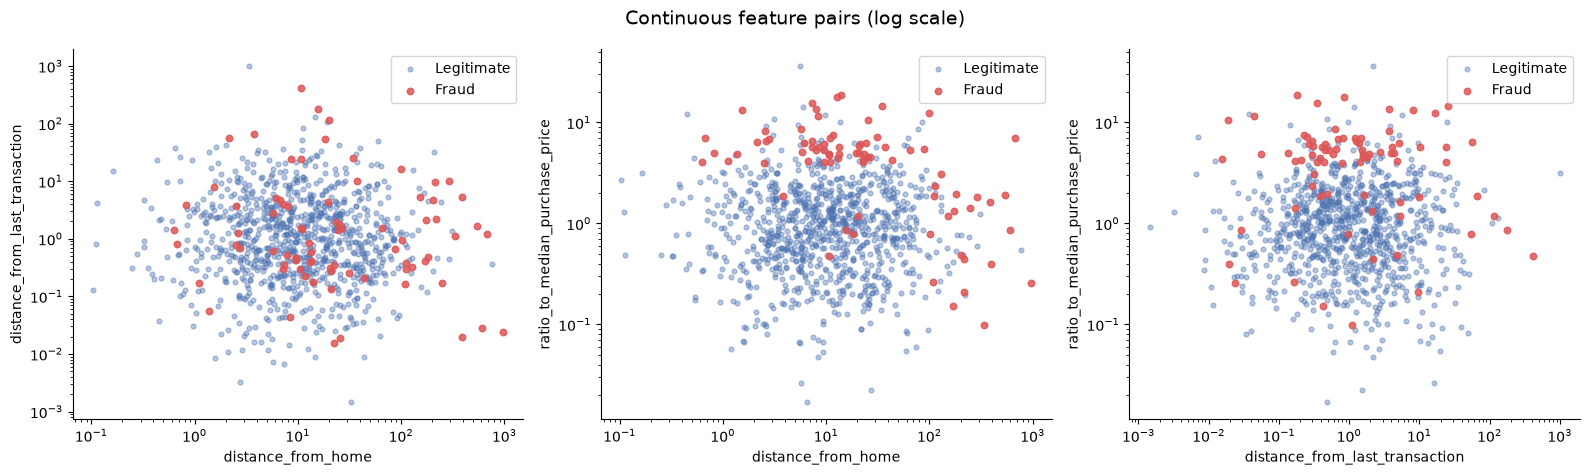

In [12]:
# Pairwise scatter plots of the continuous features (log scale), colored by class
pairs = [(0, 1), (0, 2), (1, 2)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (i, j) in zip(axes, pairs):
    x, y = continuous_cols[i], continuous_cols[j]
    for k in (0, 1):
        sub = df[df[TARGET] == k]
        ax.scatter(sub[x], sub[y], s=12 if k == 0 else 22, alpha=0.4 if k == 0 else 0.85,
                   color=CLASS_COLORS[k], label=CLASS_NAMES[k])
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.legend()
fig.suptitle("Continuous feature pairs (log scale)", fontsize=14)
plt.tight_layout()
plt.show()

Fraudulent points cluster in regions with a high purchase-price ratio **and/or** a large distance from home. Because the classes occupy different regions of feature space, a distance-based method such as KNN is a reasonable choice.

### 3.3 Binary features by class

In [13]:
# Fraud rate when each flag is 0 vs 1
summary = []
for col in binary_cols:
    for val in (0, 1):
        sub = df[df[col] == val]
        summary.append({"feature": col, "value": val, "transactions": len(sub),
                        "fraud_cases": int(sub[TARGET].sum()),
                        "fraud_rate_%": sub[TARGET].mean() * 100})
binary_summary = pd.DataFrame(summary)
binary_summary

,feature,value,transactions,fraud_cases,fraud_rate_%
0,repeat_retailer,0,107,6,5.607
1,repeat_retailer,1,885,72,8.136
2,used_chip,0,683,65,9.517
3,used_chip,1,312,13,4.167
4,used_pin_number,0,880,79,8.977
5,used_pin_number,1,117,0,0.000
6,online_order,0,325,2,0.615
7,online_order,1,670,76,11.343


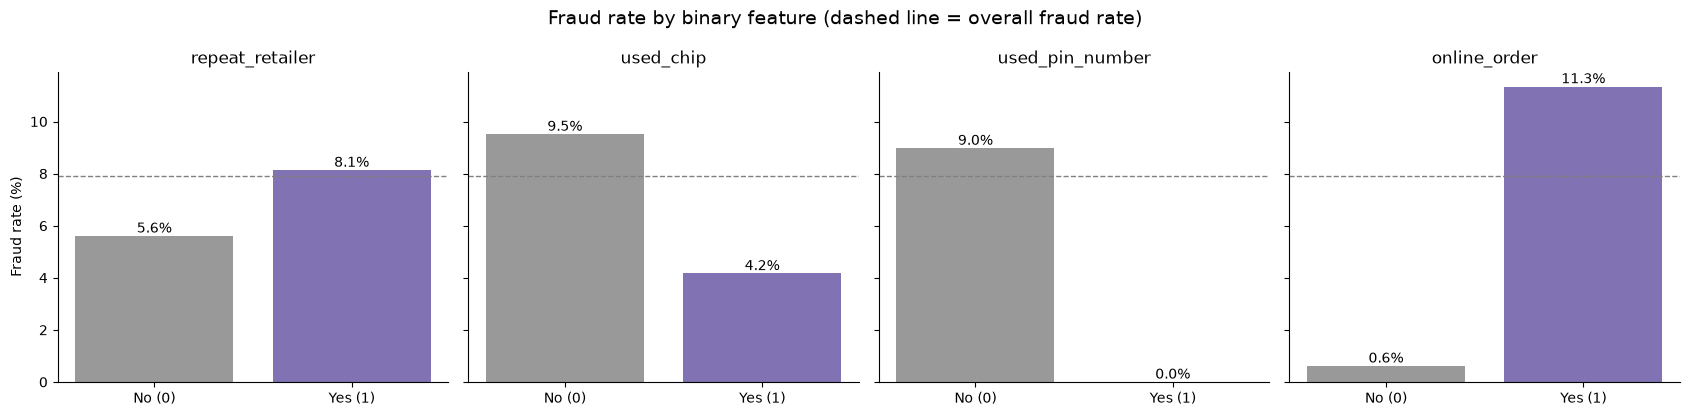

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, col in zip(axes, binary_cols):
    rates = binary_summary[binary_summary.feature == col].set_index("value")["fraud_rate_%"]
    bars = ax.bar(["No (0)", "Yes (1)"], rates.values, color=["#999999", "#8172B3"])
    for b, r in zip(bars, rates.values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{r:.1f}%", ha="center", va="bottom")
    ax.axhline(df[TARGET].mean() * 100, color="gray", ls="--", lw=1)
    ax.set_title(col)
axes[0].set_ylabel("Fraud rate (%)")
fig.suptitle("Fraud rate by binary feature (dashed line = overall fraud rate)", fontsize=14)
plt.tight_layout()
plt.show()

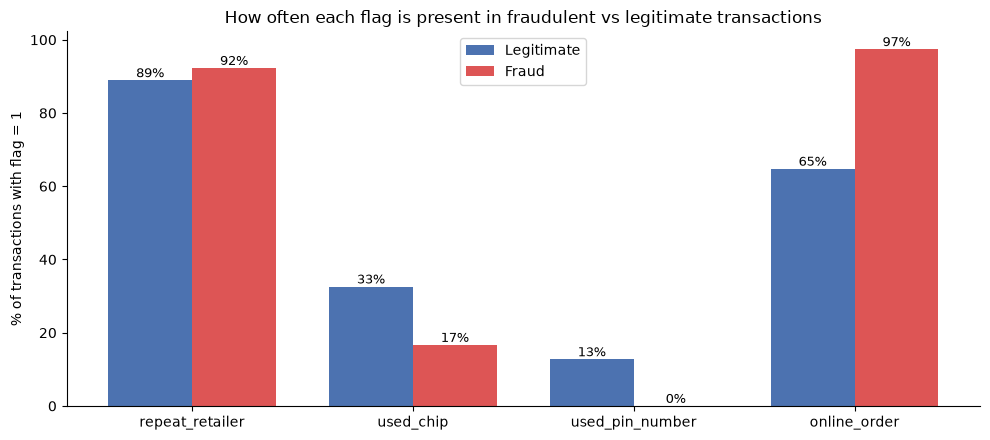

In [15]:
# Composition view: within each class, what share of transactions have each flag = 1?
share = df.groupby(TARGET)[binary_cols].mean().rename(index=CLASS_NAMES) * 100

x = np.arange(len(binary_cols))
w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
for offset, k in zip((-w / 2, w / 2), (0, 1)):
    vals = share.loc[CLASS_NAMES[k]].values
    bars = ax.bar(x + offset, vals, w, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, binary_cols)
ax.set_ylabel("% of transactions with flag = 1")
ax.set_title("How often each flag is present in fraudulent vs legitimate transactions")
ax.legend()
plt.tight_layout()
plt.show()

**Observations**
- **`online_order`**: fraud is far more common for online orders, where the physical card isn't present.
- **`used_pin_number`**: transactions that used a PIN are rarely fraudulent; a PIN is strong evidence the real cardholder was present.
- **`used_chip`**: chip transactions have a lower fraud rate than non-chip ones.
- **`repeat_retailer`**: shows little difference between the classes, so it is likely a weak predictor on its own.

In [16]:
# Combined effect: fraud rate for online orders with and without a PIN
combo = (df.dropna(subset=["online_order", "used_pin_number"])
           .groupby(["online_order", "used_pin_number"])[TARGET]
           .agg(transactions="count", fraud_rate="mean"))
combo["fraud_rate"] *= 100
combo

transactions  fraud_rate
online_order used_pin_number                          
0.000        0.000                     280       0.714
             1.000                      44       0.000
1.000        0.000                     596      12.752
             1.000                      73       0.000

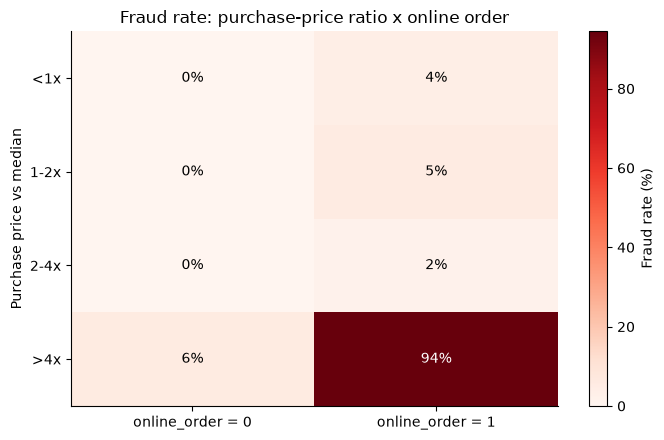

In [17]:
# Fraud rate by online order and purchase-price ratio bucket
ratio_bucket = pd.cut(df["ratio_to_median_purchase_price"], bins=[0, 1, 2, 4, np.inf],
                      labels=["<1x", "1-2x", "2-4x", ">4x"])
pivot = df.groupby([ratio_bucket, df["online_order"]], observed=True)[TARGET].mean().unstack() * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(pivot.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(pivot.shape[1]), [f"online_order = {int(c)}" for c in pivot.columns])
ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.set_ylabel("Purchase price vs median")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center",
                    color="white" if v > pivot.values[~np.isnan(pivot.values)].max() / 2 else "black")
plt.colorbar(im, label="Fraud rate (%)")
ax.set_title("Fraud rate: purchase-price ratio x online order")
plt.tight_layout()
plt.show()

Combining features is revealing: **online orders with a purchase price well above the cardholder's median** have by far the highest fraud rate. Features that look moderately useful on their own become much more informative together, which a multi-feature model like KNN can take advantage of.

### 3.4 Correlations

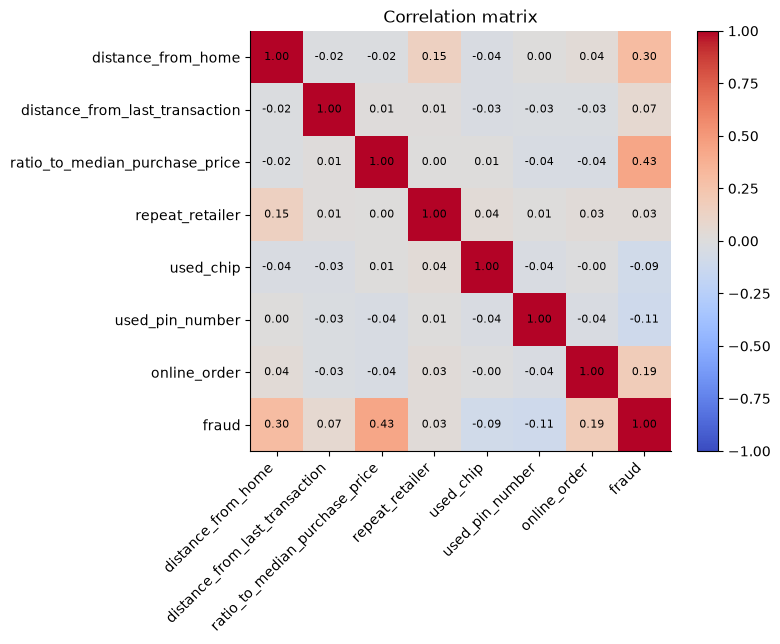

In [18]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

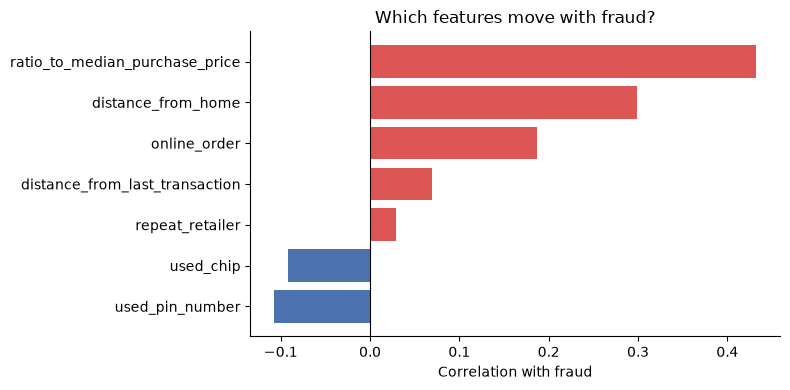

In [19]:
target_corr = corr[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(target_corr.index, target_corr.values,
        color=[CLASS_COLORS[1] if v > 0 else CLASS_COLORS[0] for v in target_corr.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlation with fraud")
ax.set_title("Which features move with fraud?")
plt.tight_layout()
plt.show()

The correlations confirm the visual findings: `ratio_to_median_purchase_price`, `online_order`, and `distance_from_home` are positively associated with fraud, while `used_pin_number` and `used_chip` are negatively associated. The features are only weakly correlated with each other, so each one adds largely independent information.

## 4. Preprocessing and train/test split

KNN classifies a point by looking at its nearest neighbors, so it is very sensitive to the **scale** of each feature. Without scaling, `distance_from_home` (values in the hundreds) would dominate the binary flags (0 or 1).

Preprocessing steps, all inside a scikit-learn `Pipeline` so they are learned from the training data only:
1. **Impute** missing values: median for continuous features, most frequent value for binary flags.
2. **Log-transform** the continuous features with `log1p` to reduce the extreme skew and limit the influence of outliers on distances.
3. **Standardize** every feature to mean 0 and standard deviation 1.

The split is **stratified** so both sets keep the ~8% fraud rate.

In [20]:
X = df[feature_cols]
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]} rows, fraud rate {y_train.mean():.2%}")
print(f"Test set:     {X_test.shape[0]} rows, fraud rate {y_test.mean():.2%}")

Training set: 749 rows, fraud rate 7.88%
Test set:     250 rows, fraud rate 8.00%


In [21]:
continuous_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])
binary_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("continuous", continuous_pipe, continuous_cols),
    ("binary", binary_pipe, binary_cols),
])

def make_knn_pipeline(**knn_params):
    return Pipeline([("prep", preprocessor), ("knn", KNeighborsClassifier(**knn_params))])

## 5. K-Nearest Neighbors model

### 5.1 Reference points: a naive baseline and a default KNN

In [22]:
def evaluate(model, X_te, y_te):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        "accuracy": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred),
        "f1": f1_score(y_te, pred),
        "roc_auc": roc_auc_score(y_te, proba),
        "pr_auc": average_precision_score(y_te, proba),
    }

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
default_knn = make_knn_pipeline(n_neighbors=5).fit(X_train, y_train)

results = pd.DataFrame({
    "Always 'legitimate'": evaluate(baseline, X_test, y_test),
    "KNN (k=5, default)": evaluate(default_knn, X_test, y_test),
}).T
results

,accuracy,precision,recall,f1,roc_auc,pr_auc
Always 'legitimate',0.920,0.000,0.000,0.000,0.500,0.080
"KNN (k=5, default)",0.980,1.000,0.750,0.857,0.970,0.900


The "always legitimate" baseline gets high accuracy but catches **zero** fraud (recall = 0), which shows why accuracy can't be the main metric here. Even the untuned KNN does far better on recall, F1, and AUC.

### 5.2 Choosing *k*: validation curve

We use 5-fold stratified cross-validation on the **training set only** to see how performance changes with the number of neighbors.

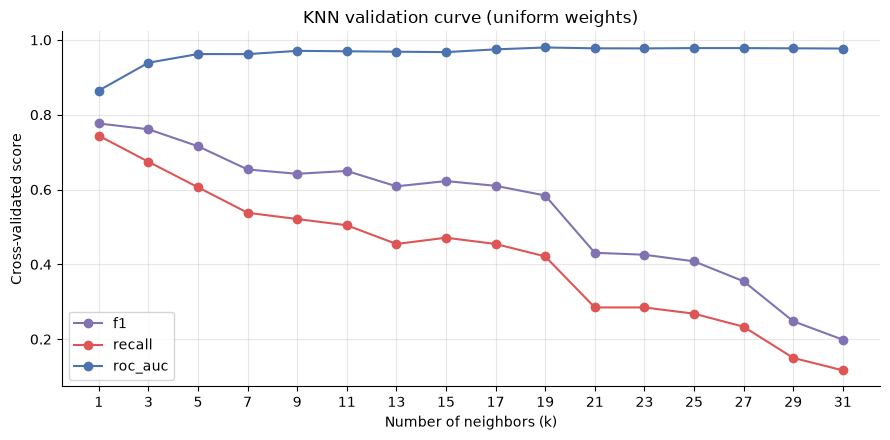

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
k_values = list(range(1, 32, 2))   # odd values avoid ties between the two classes

curve = GridSearchCV(
    make_knn_pipeline(),
    param_grid={"knn__n_neighbors": k_values},
    scoring={"f1": "f1", "recall": "recall", "roc_auc": "roc_auc"},
    refit=False, cv=cv, n_jobs=-1,
).fit(X_train, y_train)

cv_res = pd.DataFrame(curve.cv_results_)
fig, ax = plt.subplots(figsize=(9, 4.5))
for metric, color in [("f1", "#8172B3"), ("recall", CLASS_COLORS[1]), ("roc_auc", CLASS_COLORS[0])]:
    ax.plot(k_values, cv_res[f"mean_test_{metric}"], marker="o", color=color, label=metric)
ax.set_xlabel("Number of neighbors (k)")
ax.set_ylabel("Cross-validated score")
ax.set_title("KNN validation curve (uniform weights)")
ax.set_xticks(k_values)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Small values of *k* make the model react to individual noisy points, while large values smooth over the rare fraud cases (which are outnumbered by legitimate neighbors), so recall tends to fall as *k* grows. ROC-AUC, which looks at the predicted probabilities rather than the hard 0/1 decision, usually keeps improving for a while because more neighbors give smoother probability estimates.

### 5.3 Hyperparameter tuning with grid search

We tune the number of neighbors, the neighbor weighting (`uniform` vs `distance`), and the distance metric (Manhattan `p=1` vs Euclidean `p=2`). The grid search optimizes **F1**, which balances catching fraud (recall) against raising false alarms (precision).

In [24]:
param_grid = {
    "knn__n_neighbors": k_values,
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

grid = GridSearchCV(make_knn_pipeline(), param_grid, scoring="f1", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print(f"Best cross-validated F1: {grid.best_score_:.3f}")

top = (pd.DataFrame(grid.cv_results_)
         .sort_values("rank_test_score")
         [["param_knn__n_neighbors", "param_knn__weights", "param_knn__p", "mean_test_score", "std_test_score"]]
         .head(10))
top.columns = ["k", "weights", "p", "mean_F1", "std_F1"]
top

Best parameters: {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}
Best cross-validated F1: 0.794


,k,weights,p,mean_F1,std_F1
5,3,distance,1,0.794,0.123
4,3,uniform,1,0.787,0.126
3,1,distance,2,0.777,0.081
2,1,uniform,2,0.777,0.081
7,3,distance,2,0.769,0.114
13,7,distance,1,0.763,0.110
11,5,distance,2,0.761,0.112
6,3,uniform,2,0.761,0.112
1,1,distance,1,0.753,0.103
0,1,uniform,1,0.753,0.103


### 5.4 Evaluation on the held-out test set

In [25]:
best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test)
y_proba = best_knn.predict_proba(X_test)[:, 1]

results.loc["KNN (tuned)"] = evaluate(best_knn, X_test, y_test)
results

,accuracy,precision,recall,f1,roc_auc,pr_auc
Always 'legitimate',0.920,0.000,0.000,0.000,0.500,0.080
"KNN (k=5, default)",0.980,1.000,0.750,0.857,0.970,0.900
KNN (tuned),0.976,0.889,0.800,0.842,0.972,0.918


Note that the test set contains only about 20 fraud cases, so catching or missing a single one moves recall by 5 percentage points. Small differences between the default and tuned models on this test set are therefore within noise. The tuned parameters were chosen by 5-fold cross-validation, which averages over more data and is the more reliable basis for picking a model.

In [26]:
print(classification_report(y_test, y_pred, target_names=[CLASS_NAMES[0], CLASS_NAMES[1]], digits=3))

              precision    recall  f1-score   support

  Legitimate      0.983     0.991     0.987       230
       Fraud      0.889     0.800     0.842        20

    accuracy                          0.976       250
   macro avg      0.936     0.896     0.915       250
weighted avg      0.975     0.976     0.975       250



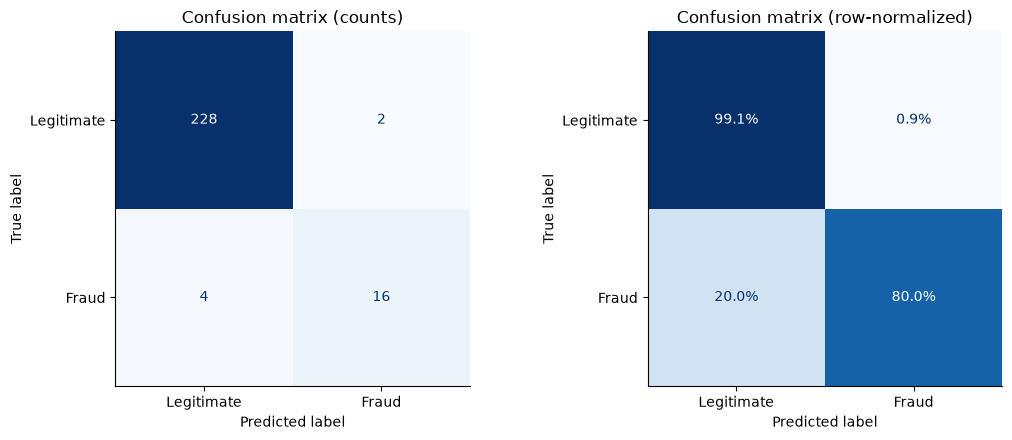

Fraud caught (TP): 16   Fraud missed (FN): 4
False alarms (FP): 2   Correctly cleared (TN): 228


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=[CLASS_NAMES[0], CLASS_NAMES[1]], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=[CLASS_NAMES[0], CLASS_NAMES[1]], cmap="Blues", ax=axes[1],
    normalize="true", values_format=".1%", colorbar=False)
axes[1].set_title("Confusion matrix (row-normalized)")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Fraud caught (TP): {tp}   Fraud missed (FN): {fn}")
print(f"False alarms (FP): {fp}   Correctly cleared (TN): {tn}")

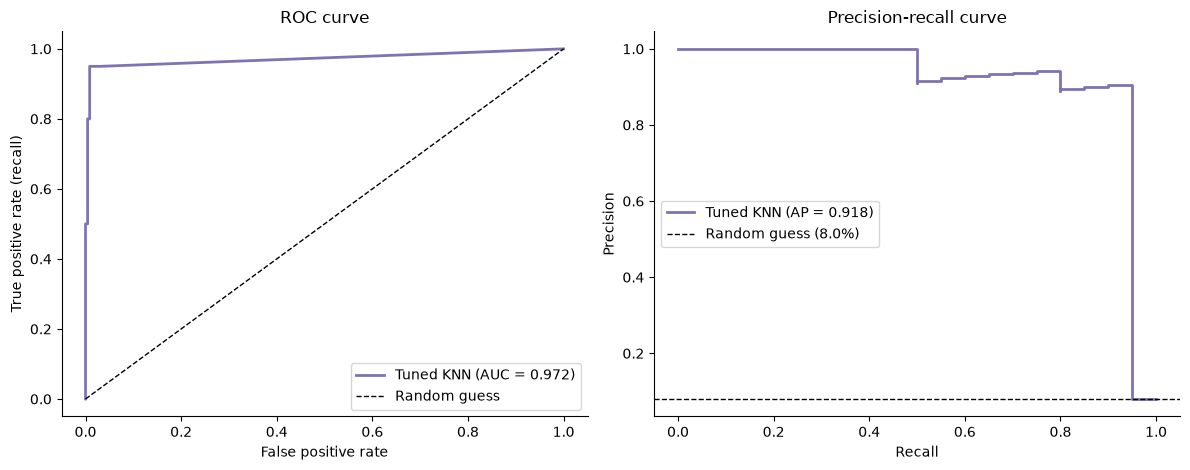

In [28]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(fpr, tpr, color="#8172B3", lw=2, label=f"Tuned KNN (AUC = {roc_auc_score(y_test, y_proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve")
axes[0].legend()

axes[1].step(rec, prec, where="post", color="#8172B3", lw=2,
             label=f"Tuned KNN (AP = {average_precision_score(y_test, y_proba):.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Random guess ({y_test.mean():.1%})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curve")
axes[1].legend()
plt.tight_layout()
plt.show()

The **ROC curve** shows how well the model ranks fraud above legitimate transactions across all thresholds. The **precision-recall curve** is more informative for imbalanced data: its random-guess baseline is the fraud rate (~8%), so a curve that stays high means the model's fraud alerts are mostly correct.

### 5.5 Adjusting the decision threshold

By default, KNN flags a transaction as fraud when more than 50% of its (weighted) neighbors are fraudulent. In fraud detection, missing a fraud is usually more costly than a false alarm, so it can be worth lowering the threshold to catch more fraud.

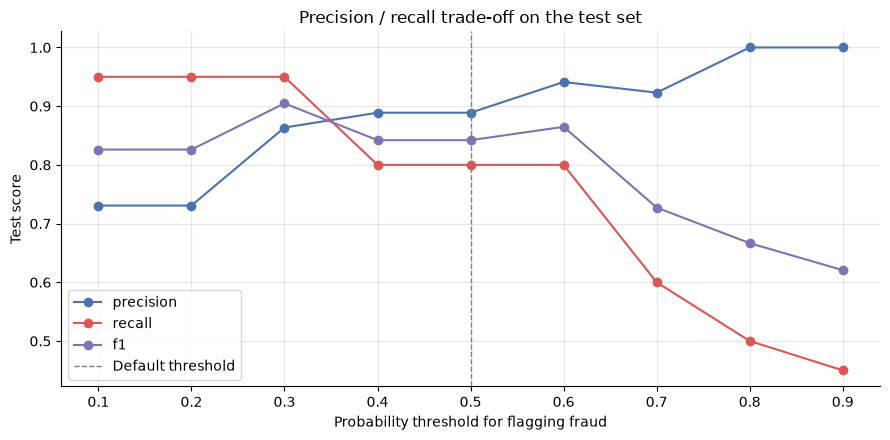

,threshold,precision,recall,f1,flagged
0,0.100,0.731,0.950,0.826,26
1,0.200,0.731,0.950,0.826,26
2,0.300,0.864,0.950,0.905,22
3,0.400,0.889,0.800,0.842,18
4,0.500,0.889,0.800,0.842,18
5,0.600,0.941,0.800,0.865,17
6,0.700,0.923,0.600,0.727,13
7,0.800,1.000,0.500,0.667,10
8,0.900,1.000,0.450,0.621,9


In [29]:
thresholds = np.round(np.arange(0.1, 0.91, 0.1), 2)
rows = []
for t in thresholds:
    pred_t = (y_proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_test, pred_t, zero_division=0),
                 "recall": recall_score(y_test, pred_t),
                 "f1": f1_score(y_test, pred_t),
                 "flagged": int(pred_t.sum())})
thresh_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
for metric, color in [("precision", CLASS_COLORS[0]), ("recall", CLASS_COLORS[1]), ("f1", "#8172B3")]:
    ax.plot(thresh_df.threshold, thresh_df[metric], marker="o", color=color, label=metric)
ax.axvline(0.5, color="gray", ls="--", lw=1, label="Default threshold")
ax.set_xlabel("Probability threshold for flagging fraud")
ax.set_ylabel("Test score")
ax.set_title("Precision / recall trade-off on the test set")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

thresh_df

Lowering the threshold raises recall (more fraud caught) at the cost of precision (more legitimate transactions flagged for review). The right threshold depends on the business cost of each type of error. Note that this table is for illustration only: properly choosing a threshold should be done with cross-validation on the training data, not by tuning on the test set.

### 5.6 Which features matter to the model?

KNN has no built-in feature importances, so we use **permutation importance**: shuffle one feature at a time in the test set and measure how much the model's F1 score drops.

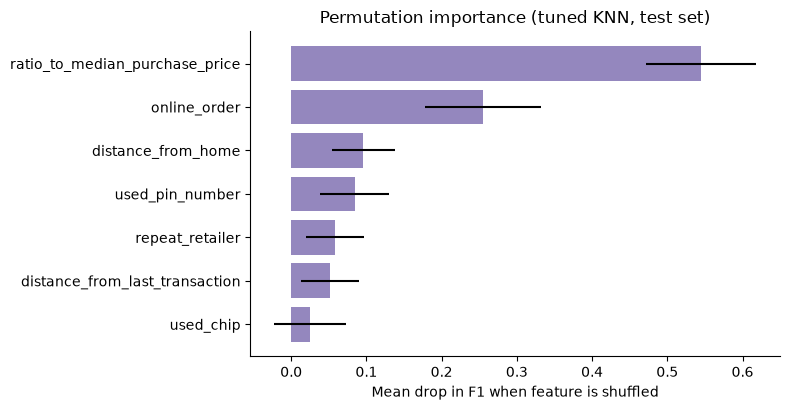

In [30]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_knn, X_test, y_test, scoring="f1",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=feature_cols).sort_values()
err = pd.Series(perm.importances_std, index=feature_cols).loc[imp.index]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(imp.index, imp.values, xerr=err.values, color="#8172B3", alpha=0.85)
ax.set_xlabel("Mean drop in F1 when feature is shuffled")
ax.set_title("Permutation importance (tuned KNN, test set)")
plt.tight_layout()
plt.show()

## 6. Conclusions

**What distinguishes fraud from legitimate transactions**
- **Purchase size relative to the cardholder's norm** (`ratio_to_median_purchase_price`) is the strongest single signal: fraudulent purchases are typically much larger than usual.
- **Online orders** carry a much higher fraud rate than in-person transactions, especially when combined with an unusually large purchase.
- **Distance from home** is higher for fraud; distance from the last transaction is a weaker version of the same signal.
- **PIN and chip usage** are protective: transactions using a PIN are almost never fraudulent in this data.
- **Repeat retailer** carries little information on its own.

**Model performance**
- Because only ~8% of transactions are fraud, accuracy is misleading (a model that never predicts fraud is ~92% accurate). Recall, precision, F1, and PR-AUC give a truer picture.
- Scaling (plus a log transform of the skewed distance/price features) is essential for KNN, since it relies on distances.
- The tuned KNN model is far better than the naive baseline at catching fraud, and its decision threshold can be adjusted to trade false alarms for a higher catch rate.

**Possible next steps**
- Choose the decision threshold with cross-validation based on the real cost of missed fraud vs. false alarms.
- Try resampling techniques (e.g., SMOTE from `imbalanced-learn`) to give KNN more fraud examples to learn from.
- Compare against other classifiers such as logistic regression, random forests, or gradient boosting.
- Train on a larger sample: with only ~250 test rows and ~20 fraud cases, the test metrics have considerable uncertainty.